# Graph Search: BFS, DFS and Dijkstra

BFS and DFS are implemented on a small graph. Dijkstra's algorithm is implemented on a real road network: the city of **Oldenburg, Germany**,
generated by T. Brinkhoff's network-based moving-objects generator and distributed by Feifei Li. Every node is a road intersection and
every edge is a road segment whose weight is its length. The source and the destination are preset for every task.

| File | Contains | Columns |
|---|---|---|
| `OL.cnode` | Intersections (nodes) | node id, x, y |
| `OL.cedge` | Road segments (edges) | edge id, start node, end node, length |

Download both files into `ASSIGNMENT_2/InClass/data/`:

- <https://users.cs.utah.edu/~lifeifei/research/tpq/OL.cnode>
- <https://users.cs.utah.edu/~lifeifei/research/tpq/OL.cedge>

**Rules:** implement every search algorithm yourself, using only the graph itself (its nodes, edges and weights). Library search functions may be used only to check your results. Use **NetworkX** to create, store and
**visualize** the graphs. Print every result asked for in a task.

In [3]:
import heapq
import math
import os
import urllib.request
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

data_dir = "../data"
base_url = "https://users.cs.utah.edu/~lifeifei/research/tpq"
os.makedirs(data_dir, exist_ok=True)

# Download the road-network files if they are not already present.
for fname in ["OL.cnode", "OL.cedge"]:
    file_path = os.path.join(data_dir, fname)
    if not os.path.exists(file_path):
        try:
            print(f"Downloading {fname} ...")
            urllib.request.urlretrieve(f"{base_url}/{fname}", file_path)
            print(f"Saved {file_path}")
        except Exception as exc:
            print(f"Could not download {fname}: {exc}")
            print(f"Please manually download {base_url}/{fname} into {data_dir}/")


#**Execution note:** Open this notebook from `InClass/src/`. The setup cell downloads `OL.cnode` and `OL.cedge` into the sibling `InClass/data/` folder if they are missing.


Saved ../data/OL.cnode
Saved ../data/OL.cedge


### The small graph (Exercise 1)

The cell below creates the graph used for BFS and DFS: a **fixed**, connected, undirected graph with 15 nodes, numbered 0 to 14.
The seed is fixed, so everybody gets the same graph. The source and the destination are preset, and `small_pos` holds fixed node positions for drawing.
Run the cell; you do not need to change it.

In [4]:
small = nx.gnp_random_graph(15, 0.2, seed=43)     # fixed seed: the same graph for everybody
assert nx.is_connected(small)
small_pos = nx.spring_layout(small, seed=42)      # fixed positions for drawing

src, dest = 0, 13                                 # preset source and destination

### Exercise 1: BFS and DFS

Source: node `0`. Destination: node `13`.

1. Load the small graph and print its number of nodes and edges.
2. Implement `bfs(G, src, dest)` and `dfs(G, src, dest)`. Each returns `(path, order)`: the path from `src` to `dest` and the list of nodes in the order they were expanded.
   Consider the neighbours of a node in increasing order of node id (DFS visits the smallest unvisited neighbour first).
   For each, print the path, its distance (number of edges) and the expansion order.
3. Using **NetworkX**, visualize the graph twice, highlighting the BFS path and the DFS path. Show `src` and `dest` in different colours.

Number of nodes: 15
Number of edges: 25

BFS
Path: [0, 3, 14, 12, 13]
Distance (number of edges): 4
Expansion order: [0, 1, 3, 9, 7, 2, 4, 11, 14, 5, 8, 10, 6, 12, 13]

DFS
Path: [0, 1, 7, 4, 11, 6, 12, 13]
Distance (number of edges): 7
Expansion order: [0, 1, 7, 4, 2, 10, 11, 6, 12, 13]


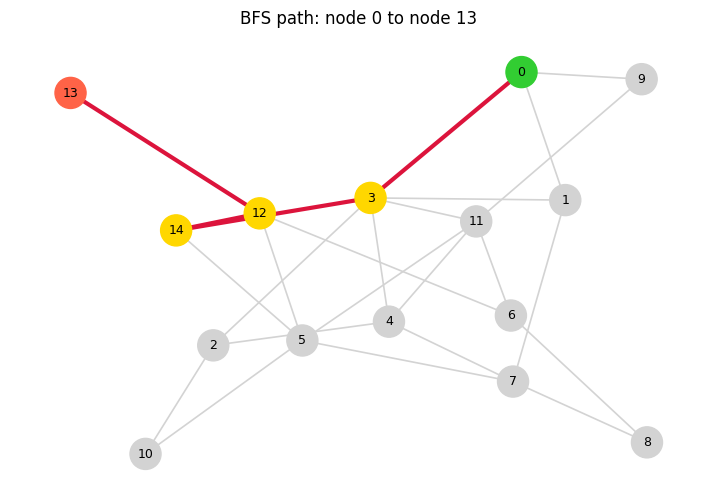

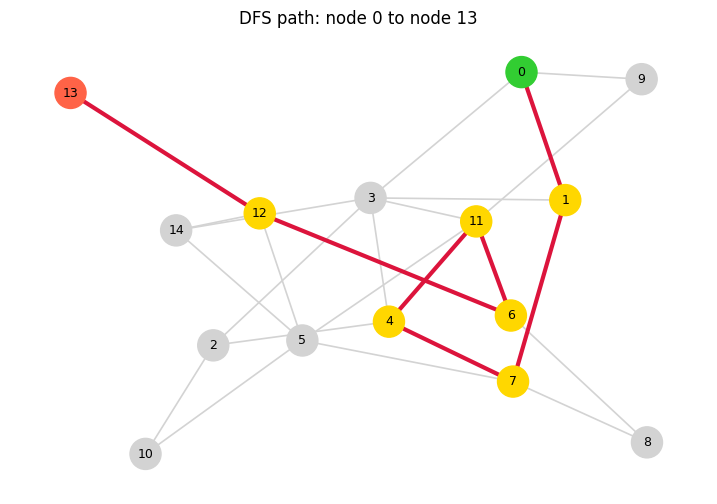

In [5]:
# 1. Load the small graph and print its number of nodes and edges
print(f"Number of nodes: {small.number_of_nodes()}")
print(f"Number of edges: {small.number_of_edges()}")

# 2. Implement BFS and DFS. The order list records nodes when they are expanded.
def bfs(G, src, dest):
    """Return (shortest_path, expansion_order) using a FIFO queue."""
    queue = deque([src])
    parent = {src: None}
    visited = {src}
    order = []

    while queue:
        u = queue.popleft()
        order.append(u)

        if u == dest:
            break

        for v in sorted(G.neighbors(u)):
            if v not in visited:
                visited.add(v)
                parent[v] = u
                queue.append(v)

    if dest not in parent:
        return [], order

    path = []
    current = dest
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()
    return path, order


def dfs(G, src, dest):
    """Return (DFS_path, expansion_order) using an explicit LIFO stack.

    Neighbours are pushed in descending order so the smallest is popped first.
    """
    stack = [src]
    parent = {src: None}
    discovered = {src}
    order = []

    while stack:
        u = stack.pop()
        order.append(u)

        if u == dest:
            break

        for v in sorted(G.neighbors(u), reverse=True):
            if v not in discovered:
                discovered.add(v)
                parent[v] = u
                stack.append(v)

    if dest not in parent:
        return [], order

    path = []
    current = dest
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()
    return path, order


bfs_path, bfs_order = bfs(small, src, dest)
dfs_path, dfs_order = dfs(small, src, dest)

print("\nBFS")
print("Path:", bfs_path)
print("Distance (number of edges):", len(bfs_path) - 1)
print("Expansion order:", bfs_order)

print("\nDFS")
print("Path:", dfs_path)
print("Distance (number of edges):", len(dfs_path) - 1)
print("Expansion order:", dfs_order)

# 3. Visualize the BFS and DFS paths separately.
def draw_search_path(G, pos, path, title):
    path_edges = list(zip(path[:-1], path[1:]))
    node_colors = []
    for node in G.nodes():
        if node == src:
            node_colors.append("limegreen")
        elif node == dest:
            node_colors.append("tomato")
        elif node in path:
            node_colors.append("gold")
        else:
            node_colors.append("lightgray")

    plt.figure(figsize=(9, 6))
    nx.draw_networkx_edges(G, pos, edge_color="lightgray", width=1.2)
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color="crimson", width=3)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=500)
    nx.draw_networkx_labels(G, pos, font_size=9)
    plt.title(title)
    plt.axis("off")
    plt.show()

draw_search_path(small, small_pos, bfs_path, "BFS path: node 0 to node 13")
draw_search_path(small, small_pos, dfs_path, "DFS path: node 0 to node 13")


### Provided for Exercise 2: preset source and destination

The **source** (node `100`) and the **destination** (node `6000`) are preset node ids of the road network, the same for everybody. Run the cell; you do not need to change it.

In [6]:
ROAD_SRC = 100         # preset source node id (from OL.cnode)
ROAD_DEST = 6000       # preset destination node id (from OL.cnode)

### Exercise 2: Dijkstra on the road network

Source: node `100`. Destination: node `6000`.

> **What is a connected component?** A connected component is a maximal set of nodes in which every node can be reached from every other node by following edges.
> A graph can have several components (for example, a few roads that are not linked to the rest of the network), and a route exists only between two nodes of the same component.
> Keep only the largest one.

1. Load the road network, keep only its largest connected component and print its number of nodes, number of edges and total road length.
2. Implement `dijkstra(G, src, dest)` following Algorithm 1 of the handout; it returns `(path, cost, expanded)`.
   Print the route length and the number of expanded nodes, and check the route length against a library function.
3. Using **NetworkX**, visualize the road network with the route highlighted. Show the source and the destination in different colours.

Largest connected component
Number of nodes: 6105
Number of edges: 7029
Total road length: 518244.68966
\nDijkstra result
Source: 100 Destination: 6000
Path: [100, 90, 88, 94, 107, 113, 5962, 5960, 5956, 5954, 2607, 2598, 2587, 2578, 2583, 2588, 2595, 2605, 2615, 5946, 5947, 5948, 2616, 2608, 2611, 5990, 5213, 5190, 5186, 5205, 5460, 5459, 5457, 2604, 2622, 2621, 2620, 2619, 810, 2702, 2703, 2704, 1522, 1520, 1499, 1497, 1496, 1490, 1462, 1460, 1455, 1451, 1448, 1443, 1446, 1450, 1459, 1465, 1467, 1476, 1486, 1492, 1498, 1503, 1511, 1513, 1525, 1536, 5883, 1180, 1175, 1166, 1156, 1152, 1125, 1103, 1095, 1078, 1075, 1079, 1085, 1097, 1108, 1116, 1117, 1124, 5993, 5994, 5995, 5997, 5998, 6000]
Route length (total road distance): 6126.947577999999
Number of edges in route: 91
Number of expanded nodes: 3535
NetworkX verification cost: 6126.947577999999
Dijkstra matches NetworkX: True


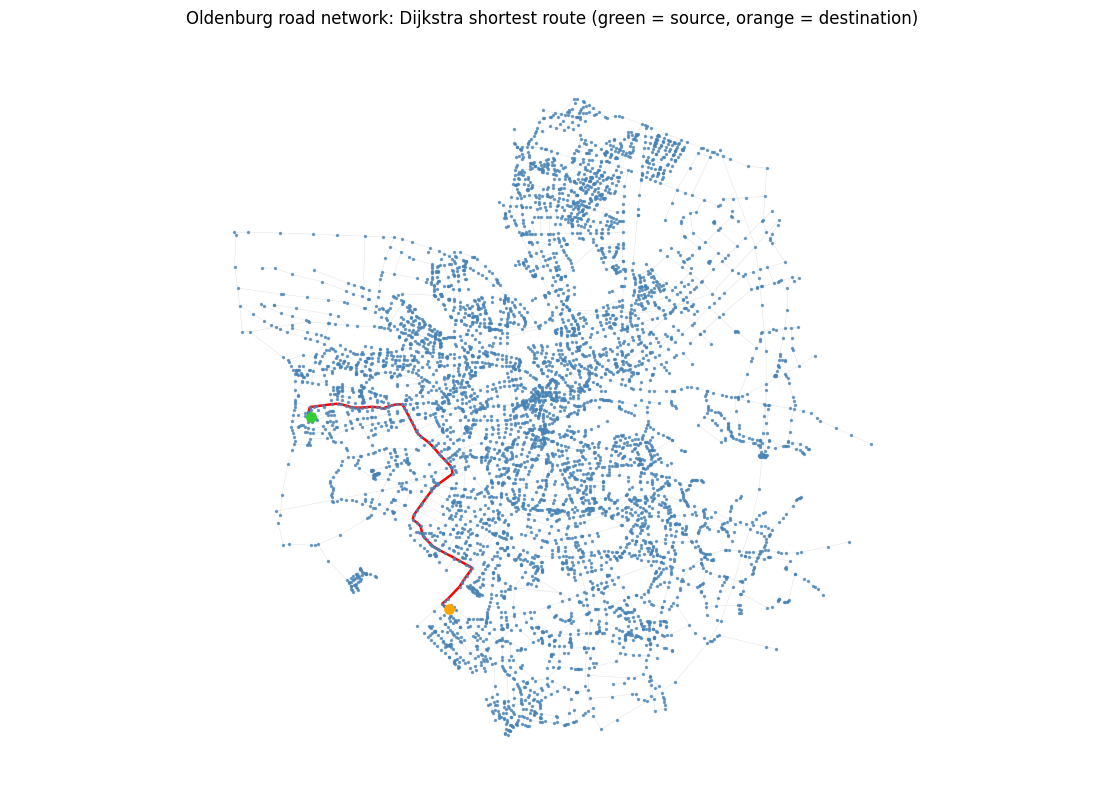

In [7]:
# 1. Load the road network (edge weight = the length column of OL.cedge).
#    Keep only its largest connected component.
node_file = os.path.join(data_dir, "OL.cnode")
edge_file = os.path.join(data_dir, "OL.cedge")
if not (os.path.exists(node_file) and os.path.exists(edge_file)):
    raise FileNotFoundError(
        "OL.cnode and/or OL.cedge are missing. Download both files into ../data/ and rerun."
    )

# The files are whitespace-separated. Lines beginning with # are ignored.
node_data = np.loadtxt(node_file, comments="#")
edge_data = np.loadtxt(edge_file, comments="#")
node_data = np.atleast_2d(node_data)
edge_data = np.atleast_2d(edge_data)

# Map each node ID to its (x, y) coordinates.
positions = {
    int(row[0]): (float(row[1]), float(row[2]))
    for row in node_data
}

G_road = nx.Graph()
G_road.add_nodes_from(positions.keys())

# OL.cedge columns: edge_id, start_node, end_node, length.
for row in edge_data:
    _, u, v, length = row
    G_road.add_edge(int(u), int(v), length=float(length))

components = list(nx.connected_components(G_road))
largest_nodes = max(components, key=len)
G_road = G_road.subgraph(largest_nodes).copy()

total_road_length = sum(data["length"] for _, _, data in G_road.edges(data=True))
print("Largest connected component")
print("Number of nodes:", G_road.number_of_nodes())
print("Number of edges:", G_road.number_of_edges())
print("Total road length:", total_road_length)

if ROAD_SRC not in G_road or ROAD_DEST not in G_road:
    raise ValueError("The preset source or destination is not in the largest connected component.")


# 2. Dijkstra's algorithm implemented from scratch.
def reconstruct_path(parent, dest):
    path = []
    current = dest
    while current is not None:
        path.append(current)
        current = parent[current]
    return path[::-1]


def dijkstra(G, src, dest):
    """Return (shortest_path, total_cost, number_of_expanded_nodes)."""
    distances = {node: math.inf for node in G.nodes()}
    distances[src] = 0.0
    parent = {src: None}
    priority_queue = [(0.0, src)]
    closed = set()
    expanded = 0

    while priority_queue:
        current_distance, u = heapq.heappop(priority_queue)

        if u in closed:
            continue
        if current_distance > distances[u]:
            continue

        closed.add(u)
        expanded += 1

        if u == dest:
            return reconstruct_path(parent, dest), distances[dest], expanded

        for v in sorted(G.neighbors(u)):
            if v in closed:
                continue
            edge_length = G[u][v]["length"]
            new_distance = distances[u] + edge_length

            if new_distance < distances[v]:
                distances[v] = new_distance
                parent[v] = u
                heapq.heappush(priority_queue, (new_distance, v))

    return [], math.inf, expanded


road_path, road_cost, road_expanded = dijkstra(G_road, ROAD_SRC, ROAD_DEST)
print("\\nDijkstra result")
print("Source:", ROAD_SRC, "Destination:", ROAD_DEST)
print("Path:", road_path)
print("Route length (total road distance):", road_cost)
print("Number of edges in route:", len(road_path) - 1)
print("Number of expanded nodes:", road_expanded)

# Independent verification using NetworkX (verification only).
verified_cost = nx.shortest_path_length(
    G_road, source=ROAD_SRC, target=ROAD_DEST, weight="length"
)
print("NetworkX verification cost:", verified_cost)
print("Dijkstra matches NetworkX:", math.isclose(road_cost, verified_cost, rel_tol=1e-9))


# 3. Visualize the road network and highlight the shortest route.
route_edges = list(zip(road_path[:-1], road_path[1:]))
road_positions = {node: positions[node] for node in G_road.nodes() if node in positions}

plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(
    G_road, road_positions, edge_color="lightgray", width=0.35, alpha=0.65
)
nx.draw_networkx_edges(
    G_road, road_positions, edgelist=route_edges, edge_color="red", width=1.8
)
nx.draw_networkx_nodes(
    G_road, road_positions, node_size=2, node_color="steelblue", alpha=0.7
)
nx.draw_networkx_nodes(
    G_road, road_positions, nodelist=[ROAD_SRC], node_size=45, node_color="limegreen"
)
nx.draw_networkx_nodes(
    G_road, road_positions, nodelist=[ROAD_DEST], node_size=45, node_color="orange"
)
plt.title("Oldenburg road network: Dijkstra shortest route (green = source, orange = destination)")
plt.axis("equal")
plt.axis("off")
plt.show()


**Before you submit:** run **Kernel → Restart & Run All** so that all outputs are visible, then push the notebook, the data files and the updated `environment.yml` and `requirements.txt` to your repository.